# Frente de ML – grade completa no teste (análise complementar)

**Objetivo:** comparar o que foi **decidido na validação (2024)** com o **resultado real no teste (01/2025 → 03/2026)** para as 12 combinações candle × janela.

⚠️ Isto **não** muda a escolha oficial da frente (`config_final.json`, decidida antes de ver o teste). A tabela responde só: *o ranking da validação se manteve no teste?*

- Modelo: Random Forest base da grade (100 árvores, profundidade 8, folha mínima de 1% do treino), o mesmo que gerou `grade_val.csv`. O modelo oficial (`rf_d4_f2`, 1 min, 12 meses) entra como linha de referência.
- Duas regras, ambas fixadas antes: **opera sempre** (sem TP/SL) e **limiar de 90%** (quantil calculado na validação 2024 de cada combinação).
- Saídas: `resultados/ml/grade_teste_complementar.csv`, `previsoes/*_teste_complementar.csv`, `validacao_vs_teste.png`.

In [1]:
import os, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
import tt1_comum as t

SAIDA = f"{PASTA}/resultados/ml"
FEATS = t.features()["COMPLETO"]
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")

class FolhaProporcional:
    # mesmo modelo base da grade em frente_ml.ipynb: min_samples_leaf = max(10, 1% das linhas de treino)
    def __init__(self, estimador, folha_frac=0.01, folha_min=10):
        self.estimador, self.folha_frac, self.folha_min = estimador, folha_frac, folha_min
    def fit(self, X, y):
        self.min_leaf_ = max(self.folha_min, int(self.folha_frac * len(X)))
        self.m = clone(self.estimador).set_params(min_samples_leaf=self.min_leaf_).fit(X, y)
        return self
    def predict(self, X):
        return self.m.predict(X)

FABRICA = lambda: FolhaProporcional(RandomForestRegressor(n_estimators=100, max_depth=8, max_features=0.5,
                                                          n_jobs=-1, random_state=42))

def estat(ops):
    x = ops[ops.lado != 0].pontos
    ep = x.std() / np.sqrt(len(x))
    return x.mean(), x.mean() / ep

def clark_west(prev, lags=10):
    y, f = prev.y_true.values, prev.y_pred.values
    adj = y ** 2 - ((y - f) ** 2 - f ** 2)
    d, n = adj - adj.mean(), len(adj)
    s2 = d @ d / n + sum(2 * (1 - l / (lags + 1)) * (d[l:] @ d[:-l]) / n for l in range(1, lags + 1))
    return adj.mean() / np.sqrt(s2 / n)

In [2]:
val = pd.read_csv(f"{SAIDA}/grade_val.csv")
linhas = []
for candle in t.CANDLES:
    df, s = t.montar_base(win, wdo, candle)
    for jm in t.JANELAS_MESES:
        prev_val = pd.read_csv(f"{SAIDA}/previsoes/WIN_{candle}_{jm}m_rf_val.csv", index_col=0, parse_dates=True)
        prev = t.walk_forward(df, FEATS, FABRICA, *t.TESTE, janela_meses=jm)
        prev.to_csv(f"{SAIDA}/previsoes/WIN_{candle}_{jm}m_rf_teste_complementar.csv")
        lim90 = t.limiar_por_quantil(prev_val, 0.9)
        linha = dict(candle=candle, janela_meses=jm, **{f"teste_{k}": v for k, v in t.metricas(prev).items()},
                     teste_cw_t=clark_west(prev))
        for nome, lim in [("sempre", 0.0), ("lim90", lim90)]:
            for custo in [0, 5]:
                ops = t.simular(prev, lim, None, None, custo)
                esp, tt = estat(ops)
                linha[f"teste_{nome}_c{custo}_esp"] = esp
                linha[f"teste_{nome}_c{custo}_t"] = tt
            linha[f"teste_{nome}_n_ops"] = int((ops.lado != 0).sum())
        # mesmas medidas na validação, para comparar
        for nome, lim in [("sempre", 0.0), ("lim90", lim90)]:
            esp, tt = estat(t.simular(prev_val, lim, None, None, 5))
            linha[f"val_{nome}_c5_esp"], linha[f"val_{nome}_c5_t"] = esp, tt
        linhas.append(linha)
        print(candle, f"{jm}m", f"teste Theil U {linha['teste_TheilU']:.4f}", f"esp(sempre, 5 pts) {linha['teste_sempre_c5_esp']:.2f}")

comp = pd.DataFrame(linhas).merge(val[["candle", "janela_meses", "TheilU", "acc_dir"]].rename(
    columns={"TheilU": "val_TheilU", "acc_dir": "val_acc_dir"}), on=["candle", "janela_meses"])
comp.to_csv(f"{SAIDA}/grade_teste_complementar.csv", index=False)

1min 1m teste Theil U 1.0017 esp(sempre, 5 pts) -4.64


1min 3m teste Theil U 1.0002 esp(sempre, 5 pts) -4.47


1min 6m teste Theil U 1.0000 esp(sempre, 5 pts) -4.26


1min 12m teste Theil U 0.9999 esp(sempre, 5 pts) -4.41


15min 1m teste Theil U 1.0124 esp(sempre, 5 pts) -5.37


15min 3m teste Theil U 1.0051 esp(sempre, 5 pts) -2.69


... (2 outputs left out)

60min 1m teste Theil U 1.0244 esp(sempre, 5 pts) -11.97


60min 3m teste Theil U 1.0150 esp(sempre, 5 pts) -9.21


60min 6m teste Theil U 1.0106 esp(sempre, 5 pts) 6.50


60min 12m teste Theil U 1.0083 esp(sempre, 5 pts) -5.69


In [3]:
from scipy.stats import spearmanr
oficial = pd.read_csv(f"{SAIDA}/teste_final.csv").query("serie == 'modelo' and custo_pts == 5").iloc[0]

cols = ["candle", "janela_meses", "val_TheilU", "teste_TheilU", "teste_cw_t", "val_sempre_c5_esp", "teste_sempre_c0_esp",
        "teste_sempre_c5_esp", "val_lim90_c5_esp", "teste_lim90_c0_esp", "teste_lim90_c5_esp", "teste_lim90_c5_t", "teste_lim90_n_ops"]
display(comp[cols].round(3))
print(f"Oficial (rf_d4_f2, 1min, 12 m, opera sempre): Theil U {oficial.TheilU:.4f} | esperança {oficial.esperanca_pts:.2f} pts/op com 5 pts")

for a, b, nome in [("val_TheilU", "teste_TheilU", "Theil U"),
                   ("val_sempre_c5_esp", "teste_sempre_c5_esp", "esperança, opera sempre"),
                   ("val_lim90_c5_esp", "teste_lim90_c5_esp", "esperança, limiar 90%")]:
    rho, p = spearmanr(comp[a], comp[b])
    print(f"Ranking validação × teste ({nome}): Spearman = {rho:.2f} (p = {p:.2f})")

,candle,janela_meses,val_TheilU,teste_TheilU,teste_cw_t,val_sempre_c5_esp,teste_sempre_c0_esp,teste_sempre_c5_esp,val_lim90_c5_esp,teste_lim90_c0_esp,teste_lim90_c5_esp,teste_lim90_c5_t,teste_lim90_n_ops
0,1min,1,1.001,1.002,2.656,-4.879,0.356,-4.644,-4.436,0.926,-4.074,-7.397,30008
1,1min,3,1.001,1.000,3.616,-4.810,0.528,-4.472,-4.577,1.609,-3.391,-6.134,29625
2,1min,6,1.000,1.000,4.074,-4.665,0.742,-4.258,-4.256,1.517,-3.483,-5.604,25275
3,1min,12,1.000,1.000,4.259,-4.787,0.590,-4.410,-3.883,2.346,-2.654,-4.695,26794
4,15min,1,1.013,1.012,-0.112,-4.743,-0.367,-5.367,-4.951,0.174,-4.826,-0.548,1523
5,15min,3,1.006,1.005,1.313,-4.626,2.309,-2.691,-3.188,-0.180,-5.180,-0.716,1967
6,15min,6,1.004,1.002,0.708,-4.400,2.278,-2.722,-2.136,2.940,-2.060,-0.204,1175
7,15min,12,1.002,1.002,-0.110,-5.458,2.179,-2.821,-1.354,-3.533,-8.533,-0.884,1449
8,60min,1,1.024,1.024,-0.802,1.029,-6.972,-11.972,-30.819,-40.197,-45.197,-1.590,457
9,60min,3,1.018,1.015,-0.749,-10.972,-4.210,-9.210,2.854,-1.147,-6.147,-0.178,340


Oficial (rf_d4_f2, 1min, 12 m, opera sempre): Theil U 0.9999 | esperança -4.41 pts/op com 5 pts
Ranking validação × teste (Theil U): Spearman = 0.99 (p = 0.00)
Ranking validação × teste (esperança, opera sempre): Spearman = -0.24 (p = 0.46)
Ranking validação × teste (esperança, limiar 90%): Spearman = 0.43 (p = 0.17)


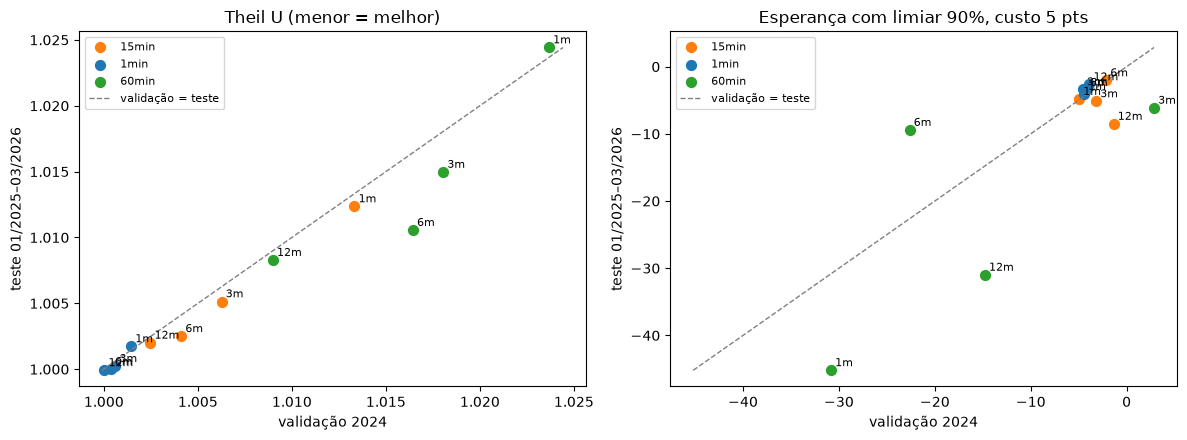

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cores = {"1min": "tab:blue", "15min": "tab:orange", "60min": "tab:green"}
for ax, (a, b, tit) in zip(axes, [("val_TheilU", "teste_TheilU", "Theil U (menor = melhor)"),
                                  ("val_lim90_c5_esp", "teste_lim90_c5_esp", "Esperança com limiar 90%, custo 5 pts")]):
    for c, g in comp.groupby("candle"):
        ax.scatter(g[a], g[b], color=cores[c], label=c, s=50)
        for r in g.itertuples():
            ax.annotate(f"{r.janela_meses}m", (getattr(r, a), getattr(r, b)), fontsize=8, xytext=(3, 3), textcoords="offset points")
    lo, hi = min(comp[a].min(), comp[b].min()), max(comp[a].max(), comp[b].max())
    ax.plot([lo, hi], [lo, hi], color="gray", ls="--", lw=1, label="validação = teste")
    ax.set_xlabel("validação 2024"); ax.set_ylabel("teste 01/2025–03/2026"); ax.set_title(tit); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/validacao_vs_teste.png", dpi=150); plt.show()